# **ĐỀ TÀI: MÔ PHỎNG VÀ ĐÁNH GIÁ HIỆU NĂNG HỆ THỐNG PHỤC VỤ KHÁCH TRONG CÔNG VIÊN GIẢI TRÍ BẰNG MẠNG HÀNG ĐỢI**

**Môn học:** Đánh giá hiệu năng hệ thống (System Performance Evaluation)

**Báo cáo Phase 1: Đặc tả hệ thống** (file nộp: `Spe-Ass-Spec-<GroupName>.pdf`)

**Nhóm:** `<GroupName>`

# 1. Team work declaration

**Thành viên nhóm**

| STT | Họ và tên | MSSV | Email |
|---|---|---|---|
| 1 | | | |
| 2 | | | |
| 3 | | | |
| 4 | | | |
| 5 | | | |
| 6 | | | |

**Bảng phân công công việc (Workmap declaration)**

| Họ tên | MSSV | Vai trò thiết kế | Vai trò cài đặt | Vai trò đánh giá | Vai trò báo cáo | Mô tả công việc Assignment 1 | Đánh giá (A/B/C) |
|---|---|---|---|---|---|---|---|
| | | | | | | | |
| | | | | | | | |
| | | | | | | | |
| | | | | | | | |

# 2. Thiết kế hệ thống (System design)

Trong các khu vui chơi giải trí, khách tham quan thường phải đi qua nhiều điểm dịch vụ như mua vé, các trò chơi, quầy ăn uống và gửi đồ. Mỗi điểm dịch vụ có số lượng nhân viên hoặc thiết bị phục vụ, sức chứa hàng chờ và thời gian phục vụ khác nhau, nên khách có thể phải xếp hàng, bị từ chối khi điểm phục vụ đã đầy, hoặc chuyển sang điểm khác sau khi hoàn thành. Trong kiến trúc này, các điểm dịch vụ liên kết với nhau thành một mạng hàng đợi, nơi tình trạng quá tải ở một điểm (như tàu lượn hay quầy kem) có thể ảnh hưởng đến luồng khách ở các điểm còn lại.

## System Performance Steps

### 1. Define Goal and System

#### Mục tiêu

**Mục tiêu tổng quát:** đánh giá hiệu năng hệ thống phục vụ khách trong công viên giải trí, xác định điểm nghẽn và mức tải mà hệ thống không còn đáp ứng được.

**Mục tiêu cụ thể:** đề tài mô phỏng một công viên giải trí gồm 6 điểm dịch vụ (quầy vé, tàu lượn, nhà ma, khu đi dạo, quầy kem, tủ gửi đồ), mục tiêu chính của bài mô phỏng bao gồm:

- Mô phỏng quá trình khách đến cổng, mua vé, chọn trò chơi theo xác suất và di chuyển giữa các điểm dịch vụ cho đến khi ra về.
- Mô phỏng quá trình tiếp nhận, xếp hàng và phục vụ tại từng điểm dịch vụ, trong đó mỗi điểm có số người phục vụ và sức chứa hàng chờ khác nhau.
- Quan sát thời gian chờ trung bình, số khách trong hàng và mức độ sử dụng của từng điểm dịch vụ.
- Quan sát và đánh giá hiện tượng quá tải, hàng chờ dài và khách bị từ chối (hàng đầy, hết tủ) trong ít nhất hai mức tải khác nhau.
- Đánh giá hiệu năng toàn hệ thống (thông lượng, tỉ lệ khách bị mất, thời gian khách ở trong công viên) và xác định điểm nghẽn.
- Phân tích mức ảnh hưởng của các yếu tố (tải đến, số khoang tàu lượn, số tủ gửi đồ, sức chứa và số nhân viên quầy kem, tỉ lệ chọn trò chơi, xác suất chơi tiếp sau khi ăn kem) đến hiệu năng của hệ thống.

**Câu hỏi quan sát:**

- Khi tải đến tăng, điểm dịch vụ nào quá tải đầu tiên?
- Tăng số khoang tàu lượn (từ 6 lên 8 hoặc 10) làm tỉ lệ khách bị mất thay đổi ra sao?
- Mở rộng hàng chờ quầy kem làm giảm khách bị từ chối, hay chỉ làm thời gian chờ dài hơn?
- Xác suất khách chơi tiếp sau khi ăn kem ($q_5$) làm tỉ lệ khách bị mất thay đổi bao nhiêu?
- Kết quả mô phỏng lệch nhiều nhất so với tính toán lý thuyết ở điểm dịch vụ nào, và nguyên nhân là gì?

**Ngưỡng tham chiếu để đánh giá (sẽ hiệu chỉnh):** tỉ lệ khách bị mất toàn hệ thống dưới 5%; thời gian chờ trung bình tại tàu lượn dưới 2 phút.

#### Hệ thống và các thông tin hỗ trợ

**Phạm vi:** từ lúc khách đến cổng đến lúc khách ra về. Không xét: giao thông đến công viên, thanh toán trực tuyến, thời tiết, nhân viên nghỉ giải lao, các loại vé khác nhau.

**Hoạt động:** khách đến theo quá trình Poisson và mua vé tại **N1**. Sau đó khách chọn theo xác suất: tàu lượn (**N2**), nhà ma (**N3**), khu đi dạo (**N4**) hoặc gửi đồ (**N6**) rồi đi chơi tiếp. Sau mỗi trò, khách quyết định ăn kem (**N5**), chơi tiếp trò khác hoặc ra về; sau khi ăn kem, khách có thể chơi tiếp hoặc ra về. Khách bị từ chối tại N2, N5, N6 (hàng đầy, hết tủ) được tính là khách bị mất.

**Các node** (đơn vị thời gian: phút):

| Node | Điểm dịch vụ | Đặc điểm | Mô hình | c | K | μ (1/phút) | Thời gian phục vụ TB |
|---|---|---|---|---|---|---|---|
| N1 | Quầy bán vé | Nhiều quầy dùng chung một hàng, hàng không giới hạn | M/M/c | 6 | ∞ | 1.0 | 1 phút |
| N2 | Tàu lượn | Nhiều khoang chạy song song, khu chờ giới hạn, đầy thì từ chối | M/M/c/K | 6 | 16 | 1/3 | 3 phút |
| N3 | Nhà ma | Một lối vào, hàng chờ coi như không giới hạn | M/M/1 | 1 | ∞ | 2.0 | 0.5 phút |
| N4 | Khu đi dạo | Không phải xếp hàng | M/M/∞ | ∞ | ∞ | 0.1 | 10 phút |
| N5 | Quầy kem | Một nhân viên, hàng chờ giới hạn | M/M/1/K | 1 | 8 | 1.2 | 50 giây |
| N6 | Tủ gửi đồ | Số tủ cố định, hết tủ thì từ chối, không có chỗ chờ | M/M/n/n | 10 | 10 | 1/30 | 30 phút |

Các giá trị (c, K, μ) là giá trị khởi điểm, sẽ hiệu chỉnh khi chạy thử.

#### Mô hình hóa toán học của hệ thống

Hệ thống được mô hình hóa theo hai tầng: mỗi điểm dịch vụ là một hàng đợi đơn, cả công viên là một mạng hàng đợi mở.

**Hàng đợi đơn** là một điểm dịch vụ trong đó khách đến, xếp hàng nếu chưa có server rảnh, được phục vụ rồi rời đi. Hàng đợi đơn được mô tả bằng ký hiệu Kendall $A/S/c/K$ (mặc định khách xếp theo thứ tự đến trước phục vụ trước, FCFS, và nguồn khách là vô hạn):

| Ký hiệu | Ý nghĩa | Trong đề tài |
|---|---|---|
| $A$ | Phân phối khoảng thời gian giữa hai lần khách đến. $A=M$ (Markov) nghĩa là khoảng cách phân phối mũ, tương đương khách đến theo quá trình Poisson; phân phối mũ “không nhớ”, nên thời gian chờ đến người tiếp theo không phụ thuộc đã chờ bao lâu | $M$ ở mọi node |
| $S$ | Phân phối thời gian phục vụ một khách. $S=M$ nghĩa là phân phối mũ với tốc độ $\mu$ (thời gian phục vụ trung bình $1/\mu$) | $M$ ở mọi node |
| $c$ | Số server phục vụ song song ($c=\infty$: khách được phục vụ ngay, không phải chờ) | 6, 6, 1, ∞, 1, 10 |
| $K$ | Sức chứa tối đa của node, gồm khách đang được phục vụ và đang chờ; khách đến khi node đã đủ $K$ thì bị từ chối ($K=\infty$: không giới hạn) | ∞, 16, ∞, ∞, 8, 10 |

**Quá trình sinh–tử.** Gọi $n$ là số khách đang có trong node (trạng thái của node). Khi có khách đến, $n$ tăng thêm 1 với tốc độ $\lambda$ (“sinh”); khi một khách được phục vụ xong, $n$ giảm đi 1 với tốc độ $\min(n,c)\,\mu$ (“tử”). Sau một thời gian đủ dài, hệ thống đạt *trạng thái dừng*: xác suất node có đúng $n$ khách tại một thời điểm bất kỳ không còn đổi, ký hiệu $P_n$. Mọi chỉ số của node (số khách, thời gian chờ, xác suất bị từ chối) được tính từ $P_n$ (mục d). Với node không giới hạn sức chứa, trạng thái dừng chỉ tồn tại khi $\rho=\lambda/(c\mu)<1$, tức tốc độ khách đến nhỏ hơn khả năng phục vụ tối đa.

**Định luật Little** liên hệ ba đại lượng trung bình của trạng thái dừng: $L=\lambda_{eff}W$ (và tương tự $L_q=\lambda_{eff}W_q$ cho phần chờ), trong đó $L$ là số khách trung bình trong node, $W$ là thời gian trung bình một khách ở trong node, và $\lambda_{eff}$ là tốc độ khách thực sự được node nhận (không tính khách bị từ chối). Định luật đúng cho mọi kiểu hàng đợi, nên dùng được để kiểm tra kết quả mô phỏng.

**Mạng hàng đợi** là tập hợp các hàng đợi đơn (node) nối với nhau: sau khi được phục vụ ở một node, khách chuyển sang node khác hoặc rời hệ thống. Có hai loại. *Mạng đóng* có số khách cố định, khách chỉ lưu thông bên trong. *Mạng mở* có khách đến từ bên ngoài và rời đi, nên số khách trong mạng thay đổi theo thời gian. Công viên là mạng mở, trong đó khách đến từ cổng, đi qua các node và ra về. Mạng có ba kiểu kết nối: *rẽ nhánh* (sau quầy vé khách chia thành 4 hướng), *hợp* (nhiều trò cùng dẫn đến quầy kem) và *phản hồi* (chơi xong có thể quay lại chơi trò khác).

**Mạng Jackson** là mạng hàng đợi mở thỏa các giả thiết sau: khách đến từ bên ngoài theo quá trình Poisson với tốc độ $\gamma_i$ vào node $i$; thời gian phục vụ phân phối mũ; kỷ luật FCFS; sau khi phục vụ ở node $j$, khách sang node $i$ với xác suất $p_{ji}$ hoặc rời mạng với xác suất $1-\sum_i p_{ji}$ (các xác suất này là *ma trận xác suất rẽ*); mọi hàng chờ không giới hạn và $\rho_i<1$ ở mọi node. Tốc độ khách đến tổng cộng $\lambda_i$ của mỗi node, gồm khách từ ngoài và khách chuyển từ các node khác, thỏa *phương trình lưu lượng* (mục b).

**Định lý dạng tích (định lý Jackson).** Khi mạng thỏa các giả thiết trên, xác suất để cùng lúc node 1 có $n_1$ khách, node 2 có $n_2$ khách, ..., node $N$ có $n_N$ khách bằng tích các xác suất của từng node: $P(n_1,\dots,n_N)=\prod_{i}P_i(n_i)$, trong đó $P_i$ là xác suất trạng thái dừng của node $i$ khi coi nó là hàng đợi riêng với tốc độ đến $\lambda_i$. Nói cách khác, ở trạng thái dừng mỗi node hoạt động như một hàng đợi độc lập. Hệ quả: số khách trung bình trong cả mạng là $L=\sum_i L_i$, và theo Little, thời gian trung bình một khách ở trong mạng là $T=L/\gamma$ (với $\gamma$ là tốc độ khách đến mạng từ bên ngoài).

Các mô hình và công thức trên được tham khảo từ: Rossetti, M.D. (2021). Simulation Modeling and Arena, 3rd and Open Text Edition. Retrieved from https://rossetti.github.io/RossettiArenaBook/ licensed under the Creative Commons Attribution-NonCommercial-NoDerivatives 4.0 International License.

**a) Cấu hình 6 mô hình.** Cả 6 mô hình là trường hợp riêng của $A/S/c/K$ với $A=S=M$, khác nhau ở cặp $(c,K)$. Ký hiệu: $\lambda$ là tốc độ đến, $\mu$ là tốc độ phục vụ của mỗi server, $a=\lambda/\mu$ (Erlang), $\rho=\lambda/(c\mu)$.

| Mô hình | Cấu hình (c, K) | Node |
|---|---|---|
| M/M/1 | c = 1, K = ∞ | N3 Nhà ma |
| M/M/1/K | c = 1, K hữu hạn | N5 Quầy kem |
| M/M/∞ | c = ∞ | N4 Khu đi dạo |
| M/M/n/n (Erlang loss) | c = n, K = n | N6 Tủ gửi đồ |
| M/M/c | c > 1, K = ∞ | N1 Quầy vé |
| M/M/c/K | c > 1, c < K < ∞ | N2 Tàu lượn |

Cả 6 mô hình được biểu diễn bằng cùng một cặp tham số (c, K): K = ∞ cho M/M/c, K = c cho M/M/n/n, c = ∞ cho M/M/∞.

**b) Mạng hàng đợi mở.** Gọi $p_{ji}$ là xác suất khách rời node $j$ sang node $i$, $\gamma_i$ là tốc độ khách đến từ ngoài vào node $i$ (chỉ $\gamma_1=\gamma$). Tốc độ đến node $i$:

$$\lambda_i=\gamma_i+\sum_j \lambda_j\,p_{ji}\quad\Longrightarrow\quad \boldsymbol\lambda=(I-P^{T})^{-1}\boldsymbol\gamma$$

Với ma trận rẽ ở mục 4, nghiệm tính theo tải được cung cấp (chưa kể khách bị mất) là: $\lambda_1=\gamma$, $\lambda_2\approx0.683\gamma$, $\lambda_3\approx0.467\gamma$, $\lambda_4\approx0.421\gamma$, $\lambda_5\approx0.471\gamma$, $\lambda_6=0.1\gamma$.

**c) Xấp xỉ lý thuyết cho cả mạng.** Công thức Jackson chỉ chính xác khi mọi hàng chờ không giới hạn. Mạng này có node hữu hạn (N2, N5) và node loại trừ (N6), nên luồng khách ra khỏi các node đó không còn là Poisson và công thức chỉ gần đúng; vì vậy hiệu năng của cả mạng được đánh giá chính bằng mô phỏng sự kiện rời rạc (DES), còn lý thuyết dùng làm mốc đối chiếu. Hai mức xấp xỉ:
- *Tải được cung cấp (offered):* dùng $\lambda_i$ ở trên, bỏ qua khách bị mất ở các node trước.
- *Xấp xỉ giảm tải (reduced):* lặp $\lambda_i=\gamma_i+\sum_j\lambda_j(1-B_j)p_{ji}$, với $B_j$ là xác suất mất tại node $j$; chính xác hơn khi tải cao.

*Node nào chính xác trong cả mạng:* N1 nhận luồng Poisson từ bên ngoài và không có khách quay lại, nên đúng là M/M/c. N6 nhận 10% luồng ra của N1; luồng ra của M/M/c ổn định là Poisson (định lý Burke) và chia ngẫu nhiên một luồng Poisson vẫn là Poisson, nên công thức Erlang B ở N6 đúng ngay trong cả mạng. N2, N3, N4, N5 nhận khách quay lại và khách bị mất ở các node trước nên chỉ là xấp xỉ.

**d) Cơ sở lý thuyết cho các chỉ số (phân bố trạng thái dừng):**

Mỗi node là một quá trình sinh–tử với trạng thái $n$ là số khách đang có trong node (đang chờ và đang được phục vụ). Cả 6 mô hình dùng chung một công thức cho xác suất trạng thái dừng $P_n$ (xác suất node có đúng $n$ khách), chỉ khác cặp $(c,K)$:

$$\tilde p_n=\begin{cases}\dfrac{a^n}{n!}, & 0\le n\le c\\[1.2em]\dfrac{a^c}{c!}\left(\dfrac{a}{c}\right)^{n-c}, & c<n\le K\end{cases}\qquad P_n=\frac{\tilde p_n}{\sum_{k=0}^{K}\tilde p_k}\qquad(a=\lambda/\mu,\ \rho=\lambda/(c\mu))$$

Dạng cụ thể của từng mô hình:

| Mô hình | Node | $(c,K)$ | Xác suất trạng thái dừng $P_n$ |
|---|---|---|---|
| M/M/1 | N3 | $(1,\infty)$ | $P_n=(1-\rho)\rho^n$, điều kiện $\rho<1$ |
| M/M/c | N1 | $(c,\infty)$ | $P_0=\left[\sum_{n=0}^{c-1}\dfrac{a^n}{n!}+\dfrac{a^c}{c!(1-\rho)}\right]^{-1}$, $P_n$ theo công thức chung, điều kiện $\rho<1$ |
| M/M/1/K | N5 | $(1,K)$ | $P_n=\dfrac{(1-\rho)\rho^n}{1-\rho^{K+1}}$ ($\rho\ne1$); $P_n=\dfrac{1}{K+1}$ ($\rho=1$) |
| M/M/c/K | N2 | $(c,K)$ | Công thức chung, $P_0$ chuẩn hóa sao cho $\sum_{n=0}^{K}P_n=1$ |
| M/M/∞ | N4 | $(\infty,\infty)$ | $P_n=e^{-a}\dfrac{a^n}{n!}$ (phân phối Poisson) |
| M/M/n/n | N6 | $(n,n)$ | $P_k=\dfrac{a^k/k!}{\sum_{j=0}^{n}a^j/j!}$, $0\le k\le n$ |



### 2. Service and Outcomes

**Dịch vụ:** bán vé (N1), tàu lượn (N2), nhà ma (N3), khu đi dạo (N4), bán kem (N5), gửi đồ (N6).

**Kết quả của một khách tại một node:**

| Kết quả | Mô tả | Ghi nhận |
|---|---|---|
| Phục vụ thành công | Khách hoàn thành dịch vụ và đi tiếp | Thời gian chờ và thời gian phục vụ của node |
| Bị từ chối | Hàng đầy (N2 đạt K=16, N5 đạt K=8) hoặc hết tủ (N6) | Bộ đếm mất của node, khách rời hệ thống |
| Ra về | Khách hoàn tất và ra Sink | Thời gian khách ở trong công viên |

**Kết quả thu được:** bảng chỉ số từng node và toàn hệ thống, đối chiếu mô phỏng với lý thuyết, biểu đồ chỉ số theo tải, điểm nghẽn và cấu hình khuyến nghị.

### 3. Select Metrics

Chọn các chỉ số đánh giá hiệu năng (metrics) bám sát mục tiêu và hệ thống ở mục 1, chia thành 3 nhóm: chỉ số tại từng node, chỉ số toàn hệ thống và chỉ số về độ tin cậy của kết quả. Mỗi chỉ số nêu rõ định nghĩa, cách đo trong mô phỏng, công thức lý thuyết để đối chiếu và ý nghĩa.

**Quy ước chung:**
- Chỉ tính sau thời gian khởi động: $T_{obs} = T_{end} - T_{warm\text{-}up}$ 
- Khách bị từ chối tại N2, N5 hoặc N6 rời hệ thống ngay, nên mỗi khách bị từ chối nhiều nhất một lần.
- Chỉ số theo node chỉ tính khách được node nhận; khách bị từ chối chỉ được đếm trong $P_{loss}$.
- Ký hiệu: $a_i=\lambda_i/\mu_i$ (Erlang), $\rho_i=\lambda_i/(c_i\mu_i)$, $B_i$ là xác suất mất tại node $i$.

#### Các chỉ số đánh giá tại từng node (Node-level)

Dùng để hiểu hành vi của từng điểm dịch vụ, tìm điểm nghẽn (bottleneck) và **Verification** từng mô hình hàng đợi (M/M/c, M/M/c/K, M/M/1, M/M/∞, M/M/1/K, M/M/n/n) bằng cách so với công thức lý thuyết.

- **Tốc độ vào hiệu dụng / thông lượng node ($\lambda_{eff,i}$):**
  + **Định nghĩa:** số khách thực sự được node $i$ nhận phục vụ trong một phút (không tính khách bị từ chối).
  + **Công thức (mô phỏng):** $\lambda_{eff,i}=\dfrac{\text{Số khách được nhận vào node } i}{T_{obs}}$
  + **Công thức (lý thuyết):** $\lambda_{eff,i}=\lambda_i(1-P_{loss,i})$; với N1, N3, N4 không có mất nên $\lambda_{eff,i}=\lambda_i$.
  + **Ý nghĩa:** là đầu vào của định luật Little và của $\rho_i$. Nếu dùng $\lambda_i$ thay cho $\lambda_{eff,i}$ ở N2, N5, N6 thì kết quả sẽ sai vì khách bị từ chối không được phục vụ.

- **Độ sử dụng server ($U_i$):**
  + **Định nghĩa:** tỉ lệ thời gian trung bình mà server của node $i$ bận phục vụ.
  + **Công thức (mô phỏng):** 
    $$U_i=\dfrac{\int_{0}^{T_{obs}} \text{(số server bận)}(t)\,dt}{c_i\cdot T_{obs}}$$
  + **Công thức (lý thuyết):** 
    $$U_i=\dfrac{\lambda_{eff,i}}{c_i\mu_i}$$
    Riêng N1 và N3 (hàng chờ không giới hạn) cần $U_i<1$ để hệ thống ổn định. Riêng N6 dùng độ sử dụng mỗi tủ:
    $$U_6=\dfrac{a_6(1-B_6)}{n_6}$$
    N4 có $c=\infty$ nên không có $U$; thay bằng số khách trung bình đang đi dạo $L_4=\lambda_4/\mu_4$.
  + **Ý nghĩa:** giúp xác định các nút cần theo dõi để phát hiện điểm nghẽn. Không thể kết luận một nút là điểm nghẽn chỉ vì $U_i$ tiến gần 1; với nút có sức chứa hữu hạn, khách còn có thể bị từ chối khi hàng đợi đầy. Vì vậy, cần xét thêm xác suất từ chối và thời gian chờ. Ở mức tải cao, N5, N2 và N3 là các nút cần theo dõi.

- **Số khách chờ trung bình ($L_{q,i}$) và số khách trung bình trong node ($L_i$):**
  + **Định nghĩa:** $L_{q,i}$ là số khách trung bình đang xếp hàng chờ; $L_i$ là số khách trung bình trong node, gồm cả khách đang chờ và đang được phục vụ.
  + **Công thức (mô phỏng):** 
    $$L_i=\dfrac{1}{T_{obs}}\int_{0}^{T_{obs}}N_i(t)\,dt$$
    trong đó $N_i(t)$ là số khách trong node $i$ tại thời điểm $t$; $L_{q,i}$ tính tương tự nhưng chỉ đếm khách đang chờ. N4 và N6 không có hàng chờ nên $L_q=0$.
  + **Công thức (lý thuyết):** tính từ xác suất trạng thái dừng $P_n$ ở mục d):
    - N1 (M/M/c): $L_q=\dfrac{a^c\rho}{c!(1-\rho)^2}P_0$, $L=L_q+a$.
    - N3 (M/M/1): $L=\dfrac{\rho}{1-\rho}$, $L_q=\dfrac{\rho^2}{1-\rho}$.
    - N2 (M/M/c/K), N5 (M/M/1/K): $L=\sum_{n=0}^{K}nP_n$, $L_q=\sum_{n=c+1}^{K}(n-c)P_n$ (với N5, $c=1$: $L_q=L-(1-P_0)$).
    - N4 (M/M/∞): $L=a_4=\dfrac{\lambda_{eff,4}}{\mu_4}$.
    - N6 (M/M/n/n): $L=a_6(1-B_6)$.
  + **Ý nghĩa:** cho biết số khách trung bình đang chờ và đang ở trong node, làm căn cứ đánh giá tình trạng quá tải và lựa chọn sức chứa $K$ (16 chỗ ở tàu lượn, 8 chỗ ở quầy kem). Dùng để kiểm tra định luật Little: $L_i=\lambda_{eff,i}W_i$ và $L_{q,i}=\lambda_{eff,i}W_{q,i}$, trong đó các đại lượng phải được tính trên cùng nhóm khách và cùng khoảng quan sát.

- **Thời gian chờ trung bình ($W_{q,i}$) và thời gian trong node ($W_i$):**
  + **Định nghĩa:** $W_{q,i}$ là thời gian trung bình từ lúc khách đến node tới lúc bắt đầu được phục vụ; $W_i=W_{q,i}+$ thời gian phục vụ.
  + **Công thức (mô phỏng):**
    $$\bar{W}_{q,i}=\dfrac{1}{N_{q,i}}\sum_{j=1}^{N_{q,i}}(\text{bắt đầu phục vụ}_j-\text{đến}_j)$$
    $$\bar{W}_i=\dfrac{1}{N_{W,i}}\sum_{j=1}^{N_{W,i}}(\text{xong}_j-\text{đến}_j)$$
    Trong đó $N_{q,i}$ là số khách đã bắt đầu được phục vụ và có dữ liệu thời gian chờ hoàn chỉnh; $N_{W,i}$ là số khách đã hoàn thành toàn bộ quá trình tại node và có dữ liệu thời gian trong node hoàn chỉnh.
  + **Công thức (lý thuyết):** theo Little (mục d), $W_i=L_i/\lambda_{eff,i}$ và $W_{q,i}=L_{q,i}/\lambda_{eff,i}$. Dạng riêng:
    - N1 (M/M/c): $W_q=\dfrac{L_q}{\lambda}$, $W=W_q+\dfrac{1}{\mu}$.
    - N3 (M/M/1): $W=\dfrac{1}{\mu-\lambda}$, $W_q=\dfrac{\rho}{\mu-\lambda}$.
    - N4: $W=1/\mu_4=10$ phút, $W_q=0$. N6: $W=1/\mu_6=30$ phút, $W_q=0$.
  + **Lưu ý:** chỉ lấy các khách đã hoàn thành giai đoạn tương ứng để tính trung bình. Khách vẫn đang chờ tại thời điểm kết thúc mô phỏng chưa có thời điểm bắt đầu phục vụ nên chưa thể tính $W_q$. Khách đã bắt đầu phục vụ nhưng chưa hoàn thành cũng chưa có $W$ đầy đủ. Đây là dữ liệu bị kiểm duyệt ở cuối khoảng quan sát (right-censoring), không đưa vào phép tính trung bình tương ứng.
  + **Ý nghĩa:** chỉ số quan trọng để **Verification** (so sánh $W_{q,sim}$ với $W_{q,theory}$). $W_{q,2}$ còn dùng để so với ngưỡng tham chiếu 2 phút của tàu lượn.

- **Độ lệch chuẩn và phân vị của thời gian chờ ($Std(W_{q,i})$, $p_{90}$, $p_{95}$):**
  + **Định nghĩa:** đo mức phân tán của thời gian chờ từng khách quanh giá trị trung bình $\bar{W}_{q,i}$.
  + **Công thức (mô phỏng):** $Std(W_{q,i})=\sqrt{\dfrac{1}{N-1}\sum_{j=1}^{N}\left(W_{q,j}-\bar{W}_{q,i}\right)^2}$; $p_{90}$, $p_{95}$ lấy từ các mẫu $W_{q,j}$ đã sắp xếp.
  + **Công thức (lý thuyết):** chỉ có dạng đóng cho node có hàng chờ không giới hạn: N3: $P(W_q>t)=\rho e^{-(\mu-\lambda)t}$; N1: $P(W_q>t)=C(c,a)\,e^{-(c\mu-\lambda)t}$, với $C(c,a)$ là xác suất phải chờ (Erlang C).
  + **Ý nghĩa:** trung bình có thể che giấu vấn đề: ví dụ thời gian chờ trung bình ở tàu lượn dưới 2 phút nhưng một nhóm khách vẫn phải chờ rất lâu. $Std$ và $p_{90}$ cho thấy mức công bằng và độ trễ đuôi mà ngưỡng "dưới 2 phút" không phản ánh.
  + **Lưu ý:** các mẫu trong cùng một lần chạy tương quan với nhau nên khoảng tin cậy được lấy theo từng lần chạy (mỗi lần cho một giá trị), không coi từng khách là mẫu độc lập.

- **Xác suất khách bị từ chối tại node ($P_{loss,i}$, chỉ N2, N5, N6):**
  + **Định nghĩa:** xác suất một khách đến node $i$ bị từ chối vì hàng đầy (N2, N5) hoặc hết tủ (N6).
  + **Công thức (mô phỏng):** $P_{loss,i}=\dfrac{\text{Số khách bị từ chối tại node } i}{\text{Số khách đến node } i}$
  + **Công thức (lý thuyết):**
    - N2: $P_{loss}=P_K=\dfrac{a^K}{c!\,c^{K-c}}P_0$ với $K=16$ ($P_0$ chuẩn hóa ở mục d)).
    - N5: $P_{loss}=P_K=\dfrac{(1-\rho)\rho^K}{1-\rho^{K+1}}$ với $K=8$, $\rho=\lambda/\mu$.
    - N6: $P_{loss}=B(n,a)$ (Erlang B), tính truy hồi $B(k)=\dfrac{aB(k-1)}{k+aB(k-1)}$ với $n=10$.
  + **Ý nghĩa:** chỉ số *bắt buộc* phải đo để so với $P_K$ lý thuyết (khi khách đến node theo Poisson, tỉ lệ khách bị từ chối theo số khách đến bằng xác suất node đầy, tính chất PASTA; điều này đúng khi kiểm tra node riêng và tại N6). Dùng để trả lời câu hỏi cần bao nhiêu tủ để $P_{loss,6}<5\%$.
  + **Lưu ý:** trong cả mạng, lý thuyết chính xác ở N1 và N6 (xem mục c); ở N2 và N5, luồng đến không còn Poisson do khách quay lại và khách bị mất ở các node trước, nên chỉ là xấp xỉ (hai mức "offered" và "reduced").

#### Các chỉ số đánh giá toàn hệ thống (System-level)

Dùng để đánh giá hiệu năng tổng thể của công viên, từ lúc khách đến cổng cho đến lúc khách ra về hoặc bị từ chối.

- **Thông lượng hệ thống ($X$):**
  + **Định nghĩa:** số khách hoàn tất hành trình và ra về qua Sink trong một phút.
  + **Công thức (mô phỏng):** $X=\dfrac{\text{Số khách ra Sink}}{T_{obs}}$
  + **Công thức (lý thuyết, xấp xỉ giảm tải):** $X\approx\gamma\,(1-P_{loss,sys})$
  + **Ý nghĩa:** hiệu quả thực tế của hệ thống. Luôn $X\le\gamma$; phần chênh lệch chính là khách bị mất.

- **Tỉ lệ khách bị mất toàn hệ thống ($P_{loss,sys}$):**
  + **Định nghĩa:** xác suất một khách đến cổng bị từ chối tại một node nào đó (N2, N5 hoặc N6) trong hành trình.
  + **Công thức (mô phỏng):** $P_{loss,sys}=\dfrac{\text{Số khách bị từ chối (ở mọi node)}}{\text{Số khách đến cổng}}$
  + **Công thức (lý thuyết, xấp xỉ):** $P_{loss,sys}\approx\dfrac{\sum_{i\in\{2,5,6\}}\lambda_iB_i}{\gamma}$
  + **Ý nghĩa:** đo độ tin cậy của hệ thống, so với ngưỡng tham chiếu 5% ở mục 1. Vì chỉ số này gộp ba loại từ chối khác nhau nên báo cáo kèm $P_{loss,i}$ của từng node: bị từ chối ở N5 (quầy kem) xảy ra sau khi khách đã chơi, còn ở N2 thì khách chưa được chơi trò đó.

- **Thời gian khách ở trong công viên ($T_{park}$):**
  + **Định nghĩa:** thời gian từ lúc khách đến cổng đến lúc ra về, chỉ tính khách ra về.
  + **Công thức (mô phỏng):** $\bar{T}_{park}=\dfrac{1}{M}\sum_{j=1}^{M}(\text{ra về}_j-\text{đến cổng}_j)$ với $M$ là số khách ra về; báo cáo thêm $p_{90}$.
  + **Công thức (lý thuyết):** $T_{park}\approx L_{sys}/X$ (Little cho toàn hệ thống).
  + **Ý nghĩa:** thể hiện trải nghiệm tổng thể của khách trong công viên.

- **Số khách trong công viên ($L_{sys}$):**
  + **Định nghĩa:** số khách trung bình đang ở trong toàn công viên (đang xếp hàng hoặc đang được phục vụ ở mọi node).
  + **Công thức:** $L_{sys}=\sum_{i=1}^{6}L_i$ (đo bằng trung bình theo thời gian của số khách trong công viên, và so với tổng lý thuyết).
  + **Ý nghĩa:** đo mức đông đúc chung của công viên. Chỉ liên hệ với $T_{\text{park}}$ qua định luật Little khi $X$ và $T_{\text{park}}$ được tính trên cùng nhóm khách với $L_{\text{sys}}$. Nếu $L_{\text{sys}}$ tính cả khách bị từ chối ở các node, còn $X$ chỉ tính khách hoàn tất hành trình và rời hệ thống qua Sink, thì không dùng trực tiếp $L_{\text{sys}}=X\cdot T_{\text{park}}$.

- **Số điểm dịch vụ mỗi khách ghé ($V$):**
  + **Định nghĩa:** số lần trung bình một khách vào điểm dịch vụ (tính cả quầy vé).
  + **Công thức (mô phỏng):** trung bình số lượt vào node của mỗi khách ra về.
  + **Công thức (lý thuyết):** $V=\sum_{i=1}^{6}\lambda_i/\gamma\approx3{,}14$ (theo $\lambda_i$ ở tải được cung cấp), chính xác khi mất khách nhỏ.
  + **Ý nghĩa:** kiểm tra ma trận xác suất rẽ trong mô phỏng có khớp với lý thuyết.

- **Điểm nghẽn và ngưỡng tải ($\gamma_{max,i}$):**
  + **Định nghĩa:** điểm nghẽn là node có $\rho_i$ lớn nhất, hoặc có $P_{loss}$ tăng sớm nhất, khi tăng $\gamma$.
  + **Công thức (lý thuyết):** ngưỡng tải mà $\rho_i$ (theo $\lambda_i$ được cung cấp) chạm 1: $\gamma_{max,i}=\dfrac{c_i\mu_i}{\lambda_i/\gamma}$. Với tham số ở mục 1: N5 $\approx2{,}55$; N2 $\approx2{,}93$; N3 $\approx4{,}28$; N1 $=6$. N4 không có ngưỡng ($c=\infty$); N6 là hệ thống mất nên xét theo $P_{loss,6}$.
  + **Ý nghĩa:** trả lời câu hỏi điểm dịch vụ nào quá tải đầu tiên khi tải tăng. Đây là giá trị xấp xỉ, sẽ đối chiếu với kết quả mô phỏng khi quét $\gamma$.

#### Các chỉ số về độ tin cậy của kết quả

Mỗi chỉ số trên cho một giá trị $x_k$ ở mỗi lần chạy $k=1,\dots,R$ ($R=30$, mỗi lần một seed khác nhau).

- **Khoảng tin cậy 95% (t-Student):** $\bar{x}\pm t_{0.975,\,R-1}\cdot\dfrac{s}{\sqrt{R}}$, với $\bar{x}$, $s$ là trung bình và độ lệch chuẩn của $x_1,\dots,x_R$; khi $R=30$ thì $t_{0.975,29}\approx2{,}045$.
- **Sai số tương đối so với lý thuyết:** $\varepsilon=\dfrac{|x_{sim}-x_{theory}|}{x_{theory}}$. Kết quả được xem là khớp khi khoảng tin cậy 95% chứa giá trị lý thuyết. Chỉ so ở node có nghiệm lý thuyết chính xác; ở cả mạng, chênh lệch được giải thích bằng tính xấp xỉ của lý thuyết, không coi là lỗi mô phỏng.
- **Kiểm tra định luật Little:** $\dfrac{|L_i-\lambda_{eff,i}W_i|}{L_i}$ cho từng node và $\dfrac{|L_{sys}-X\,T_{park}|}{L_{sys}}$ cho toàn hệ thống; giá trị phải gần 0.
- **Bảo toàn khách:** Tổng số khách có mặt trong hệ thống tại thời điểm bắt đầu thống kê và số khách đến cổng trong thời gian thống kê bằng tổng số khách ra về, số khách bị từ chối và số khách còn trong công viên tại thời điểm kết thúc thống kê.
$
N_{\text{start}} + N_{\text{arrived}}
= N_{\text{departed}} + N_{\text{lost}} + N_{\text{remaining}}
$
### 4. List System Parameters

**Tham số từng node:** xem bảng ở mục 1. Tên tham số trong thiết kế:

| Tham số | Ý nghĩa | Công thức |
|---|---|---|
| `mean_interarrival_time` | Thời gian đến trung bình ở cổng | $1/\gamma$ |
| `mean_servicetime` | Thời gian phục vụ trung bình của một server | $1/\mu$ |
| `maxServer` | Số server của node | $c$ |
| `maxSystemSize` | Sức chứa node (đang phục vụ + đang chờ) | $K$ |

**Ma trận xác suất rẽ** (phần còn lại của mỗi hàng là xác suất ra về):

| Từ \ Đến | N1 | N2 | N3 | N4 | N5 | N6 | Ra về |
|---|---|---|---|---|---|---|---|
| N1 Quầy vé | 0 | 0.45 | 0.25 | 0.20 | 0 | 0.10 | 0 |
| N2 Tàu lượn | 0 | 0 | 0.15 | 0.15 | 0.30 | 0 | 0.40 |
| N3 Nhà ma | 0 | 0.15 | 0 | 0.15 | 0.30 | 0 | 0.40 |
| N4 Khu đi dạo | 0 | 0.10 | 0.10 | 0 | 0.30 | 0 | 0.50 |
| N5 Quầy kem | 0 | 0.15 | 0.09 | 0.06 | 0 | 0 | 0.70 |
| N6 Tủ gửi đồ | 0 | 0.50 | 0.30 | 0.20 | 0 | 0 | 0 |

Các hàng N2–N4 gộp hai quyết định liên tiếp của khách: *quyết định tiếp theo* (ăn kem 0.30 / chơi tiếp 0.30 / ra về 0.40 sau tàu lượn và nhà ma; 0.30 / 0.20 / 0.50 sau khu đi dạo), rồi *chọn trò tiếp theo* (chia đều cho hai trò còn lại). Ví dụ N2 → N3: 0.30 × 0.5 = 0.15. Hàng N5 có hai thông số: xác suất chơi tiếp sau khi ăn kem $q_5=0.30$ (bằng xác suất chơi tiếp sau tàu lượn và nhà ma) và tỉ lệ chọn trò 0.5 / 0.3 / 0.2 cho N2 / N3 / N4 (giống sau tủ gửi đồ); còn lại $1-q_5=0.70$ ra về. Các xác suất rẽ là giả định của nhóm về hành vi của khách, không lấy từ số liệu đo; ảnh hưởng của chúng được khảo sát ở các yếu tố "tỉ lệ chọn trò sau khi mua vé" và $q_5$ (mục 5).

**Tham số tải và chạy:**

| Tham số | Giá trị khởi điểm | Ghi chú |
|---|---|---|
| Phân phối khách đến | Poisson, tốc độ $\gamma$ (khách/phút) | Khoảng cách giữa hai lần đến ~ Exp($\gamma$) |
| Phân phối thời gian phục vụ | Mũ, tốc độ $\mu_i$ | Theo từng node |
| Thời gian khởi động (warm-up) | 500 phút | Không tính vào chỉ số |
| Thời gian chạy $T_{end}$ | 10 000 phút | Khoảng 20 000 khách mỗi lần chạy ở $\gamma=2$ |
| Số lần chạy lặp | 30 | Mỗi lần một seed khác nhau |
| Dispatcher | `sequential`, `distributed_sequential` | Hai loại cho kết quả tương đương |
| `bucket_width` của LadderQueue | khoảng 0.5 phút | Cỡ nửa thời gian phục vụ nhỏ nhất, tinh chỉnh khi chạy thử |

### 5. List Factors to Study

Mức in đậm là mức cơ sở:

| Yếu tố | Ký hiệu | Các mức | Lý do chọn |
|---|---|---|---|
| Tải đến | $\gamma$ (khách/phút) | 1 / **2** / 4 | Quyết định chế độ tải |
| Số khoang tàu lượn | $c_2$ | **6** / 8 / 10 | Node quá tải thứ hai theo tính sơ bộ (sau quầy kem) |
| Số tủ gửi đồ | $n_6$ | **10** / 16 | Quyết định xác suất hết tủ |
| Sức chứa quầy kem | $K_5$ | 4 / **8** / 16 | Ảnh hưởng của kích thước hàng chờ |
| Số nhân viên quầy kem | $c_5$ | **1** / 2 | Một nhân viên không đủ công suất ở tải cao (tải vào quầy kem vượt 1.2 khách/phút) |
| Xác suất chơi tiếp sau khi ăn kem | $q_5$ | 0 / **0.3** / 0.5 | $q_5=0$ là luồng không quay lại (đối chiếu); $q_5$ càng lớn thì tải vào các trò càng cao |
| Tỉ lệ chọn trò sau khi mua vé | $(p_{12},p_{13},p_{14},p_{16})$ | **(0.45, 0.25, 0.20, 0.10)** / (0.30, 0.40, 0.20, 0.10) | Chuyển tải từ tàu lượn sang nhà ma |

Ở $q_5=0.5$ và WL3, tải được cung cấp của nhà ma (N3) vượt 1 ($\rho\approx1.03$); mô phỏng vẫn ổn định vì một phần khách đã bị mất ở N2 và N5. Đổi từng yếu tố một so với cấu hình cơ sở; nếu còn thời gian, thêm thiết kế giai thừa $2^k$ cho 3 yếu tố ảnh hưởng nhất để xét tương tác.

### 6. Select Evaluation Technique

| Kỹ thuật | Nhận xét | Sử dụng |
|---|---|---|
| Mô hình giải tích | Có công thức đóng cho từng node; cả mạng chỉ gần đúng do node hữu hạn, node loại trừ và vòng quay lại | Làm mốc đối chiếu |
| **Mô phỏng sự kiện rời rạc (DES)** | Xử lý được mạng có feedback và node hữu hạn; đổi tham số dễ; chạy lặp để có khoảng tin cậy | **Kỹ thuật chính** |
| Đo đạc thực tế | Không có hệ thống thật để đo | Không dùng (tùy chọn: quan sát thời gian xếp hàng ở một khu vui chơi để đối chiếu độ lớn) |

Công cụ: thư viện `bkitevsim` (Simulation, Dispatcher, LadderQueue, `BkSysCoLogicalProcess`, `BkSysCoEventLoop`, `BkSysFuture`) kết hợp `asyncio`.

### 7. Select Workload

Workload được xác định bằng tải đến $\gamma$ (khách/phút), cấu hình mạng giữ nguyên. Giá trị kỳ vọng lấy từ bảng tính toán sơ bộ bên dưới.

| Workload | $\gamma$ | Mục đích | Kỳ vọng |
|---|---|---|---|
| WL1 Thấp | 1 | Chế độ nhẹ | Mất khách gần 0; $\rho_2\approx0.34$ |
| WL2 Cơ sở | 2 | Vận hành thông thường | $\rho_2\approx0.68$; mất tại N5 khoảng 3.3–3.5%; hết tủ N6 khoảng 4.3% |
| WL3 Cao | 4 | Quá tải, tìm điểm nghẽn | N2 mất khoảng 21–27%; N5 khoảng 24–37%; N6 khoảng 30% (giữa hai mức xấp xỉ) |

**Kịch bản thay đổi yếu tố (chạy ở WL3):**

| Kịch bản | Thay đổi so với cơ sở | Quan sát |
|---|---|---|
| S4 | $c_2=8$ và $c_2=10$ | Tác động của số khoang tàu lượn |
| S5 | $n_6=16$, đối chiếu mức tối thiểu theo Erlang B | Xác suất hết tủ |
| S6 | $K_5=4$ và $K_5=16$ | Tác động của sức chứa hàng chờ quầy kem |
| S7 | $c_5=2$ | Tác động của số nhân viên quầy kem |
| S8 | $q_5=0$ và $q_5=0.5$ | Tác động của việc chơi tiếp sau khi ăn kem |
| S9 | Tỉ lệ chọn trò (0.30, 0.40, 0.20, 0.10) | Tác động của việc chuyển tải |
| S10 | Kết hợp các thay đổi hiệu quả nhất | Cấu hình khuyến nghị (tính sơ bộ: $c_2=10$, $c_5=2$, $n_6=17$ cho tỉ lệ mất toàn hệ thống khoảng 3.7% ở WL3) |

### 8–10. Kế hoạch thí nghiệm, phân tích và trình bày (thực hiện ở Phase 2)

| Bước | Nội dung |
|---|---|
| 8. Thí nghiệm | Mỗi workload và kịch bản chạy 30 lần, seed khác nhau và cố định để tái lập, bỏ 500 phút khởi động; chạy từng node độc lập để kiểm tra mô hình |
| 9. Phân tích | Trung bình ± khoảng tin cậy 95%; sai số so với lý thuyết (offered, reduced); kiểm tra Little; xếp hạng yếu tố theo mức ảnh hưởng; giải thích sai lệch ở node sau node hữu hạn |
| 10. Trình bày | Biểu đồ chỉ số theo $\gamma$, bản đồ nhiệt độ sử dụng, bảng đối chiếu mô phỏng và lý thuyết từng node, so sánh các kịch bản S4–S10 |

**Ba hướng phân tích:**
- Đánh giá cấu hình cơ sở: so với ngưỡng tham chiếu ở mục 1.
- Phân tích độ nhạy: đổi từng yếu tố ở mục 5, xem chỉ số nào thay đổi nhiều nhất.
- Tìm cấu hình tốt hơn: thay đổi $c_2$, $c_5$, $n_6$, $K_5$ để giảm tỉ lệ khách bị mất ở WL3.

## Tính toán sơ bộ

Kết quả tính theo phương trình lưu lượng và công thức lý thuyết cho 3 workload, dùng để kiểm tra tính hợp lý của bộ tham số: node nào ổn định, node nào quá tải. Cột "Mất" là xác suất khách bị từ chối (N2, N5, N6); ρ của node có mất tính theo thông lượng thực nhận.

**WL1: γ = 1 khách/phút**

| Node | Mô hình | λ (offered) | ρ | Mất (offered) | Mất (reduced) | Wq (phút) | W (phút) | L |
|---|---|---|---|---|---|---|---|---|
| N1 Quầy vé | M/M/6 | 1.000 | 0.17 | 0.0% | 0.0% | 0.00 | 1.00 | 1.00 |
| N2 Tàu lượn | M/M/6/16 | 0.683 | 0.34 | 0.0% | 0.0% | 0.02 | 3.02 | 2.06 |
| N3 Nhà ma | M/M/1 | 0.467 | 0.23 | 0.0% | 0.0% | 0.15 | 0.65 | 0.30 |
| N4 Khu đi dạo | M/M/∞ | 0.421 | - | 0.0% | 0.0% | 0.00 | 10.00 | 4.21 |
| N5 Quầy kem | M/M/1/8 | 0.471 | 0.39 | 0.0% | 0.0% | 0.53 | 1.37 | 0.64 |
| N6 Tủ gửi đồ | M/M/10/10 | 0.100 | 0.30 | 0.1% | 0.1% | 0.00 | 30.00 | 3.00 |

Toàn hệ thống (xấp xỉ giảm tải): thông lượng ≈ 1.00 khách/phút, tỉ lệ khách bị mất ≈ 0.0%, thời gian trung bình trong công viên ≈ 11.2 phút.

**WL2: γ = 2 khách/phút**

| Node | Mô hình | λ (offered) | ρ | Mất (offered) | Mất (reduced) | Wq (phút) | W (phút) | L |
|---|---|---|---|---|---|---|---|---|
| N1 Quầy vé | M/M/6 | 2.000 | 0.33 | 0.0% | 0.0% | 0.00 | 1.00 | 2.01 |
| N2 Tàu lượn | M/M/6/16 | 1.366 | 0.68 | 0.2% | 0.2% | 0.45 | 3.45 | 4.69 |
| N3 Nhà ma | M/M/1 | 0.934 | 0.47 | 0.0% | 0.0% | 0.44 | 0.94 | 0.88 |
| N4 Khu đi dạo | M/M/∞ | 0.841 | - | 0.0% | 0.0% | 0.00 | 10.00 | 8.41 |
| N5 Quầy kem | M/M/1/8 | 0.942 | 0.76 | 3.5% | 3.3% | 1.92 | 2.75 | 2.50 |
| N6 Tủ gửi đồ | M/M/10/10 | 0.200 | 0.57 | 4.3% | 4.3% | 0.00 | 30.00 | 5.74 |

Toàn hệ thống (xấp xỉ giảm tải): thông lượng ≈ 1.96 khách/phút, tỉ lệ khách bị mất ≈ 2.1%, thời gian trung bình trong công viên ≈ 12.3 phút.

**WL3: γ = 4 khách/phút**

| Node | Mô hình | λ (offered) | ρ | Mất (offered) | Mất (reduced) | Wq (phút) | W (phút) | L |
|---|---|---|---|---|---|---|---|---|
| N1 Quầy vé | M/M/6 | 4.000 | 0.67 | 0.0% | 0.0% | 0.14 | 1.14 | 4.57 |
| N2 Tàu lượn | M/M/6/16 | 2.731 | 0.99 | 27.2% | 21.1% | 3.77 | 6.77 | 13.46 |
| N3 Nhà ma | M/M/1 | 1.868 | 0.93 | 0.0% | 0.0% | 7.05 | 7.55 | 14.10 |
| N4 Khu đi dạo | M/M/∞ | 1.683 | - | 0.0% | 0.0% | 0.00 | 10.00 | 16.83 |
| N5 Quầy kem | M/M/1/8 | 1.884 | 0.99 | 37.0% | 24.0% | 4.56 | 5.39 | 6.40 |
| N6 Tủ gửi đồ | M/M/10/10 | 0.400 | 0.84 | 30.2% | 30.2% | 0.00 | 30.00 | 8.38 |

Toàn hệ thống (xấp xỉ giảm tải): thông lượng ≈ 2.99 khách/phút, tỉ lệ khách bị mất ≈ 25.4%, thời gian trung bình trong công viên ≈ 16.8 phút.

**Nhận xét:**
- Ở WL1 và WL2, hệ thống tương đối ổn định và tỷ lệ mất khách còn nhỏ. Mất khách đáng kể đầu tiên xuất hiện ở tủ gửi đồ (N6, khoảng 4.3% ở WL2) và quầy kem (N5, khoảng 3.3–3.5% ở WL2).
- Ở WL3, tàu lượn (N2) có mức sử dụng sau khi xét chặn $\rho_{\text{eff}}\approx0.99$ và mất khoảng 21–27%; quầy kem (N5) mất khoảng 24–37%; tủ gửi đồ (N6) mất khoảng 30%. Đây là các điểm nghẽn dự kiến. Theo tính toán sơ bộ, quầy kem và tàu lượn quá tải trước ($\gamma_{\max}\approx2.55$ và $2.93$); cần kiểm chứng bằng mô phỏng.
- N1 ổn định ở WL3 ($\rho\approx0.67$; chọn $c_1=6$ để quầy vé không thành điểm nghẽn). Nhà ma (N3) gần ngưỡng ($\rho\approx0.93$ theo tải được cung cấp).
- Cơ sở lựa chọn số lượng tủ N6: N6 chỉ nhận khách từ N1 nên lưu lượng đến N6 không phụ thuộc vào xác suất routing $q_5$. Với giả thiết dòng khách đến tuân theo phân phối Poisson, có thể sử dụng công thức Erlang B để ước tính xác suất tất cả các tủ đều bận. Kết quả ước tính cho thấy cần khoảng 10 tủ ở WL2 ($\gamma=2$) và 17 tủ ở WL3 ($\gamma=4$) để xác suất mất khách tại N6 nhỏ hơn 5%. Vì vậy, nhóm chọn 17 lockers cho WL3 nhằm đáp ứng mục tiêu tỷ lệ mất khách dưới 5% tại riêng node N6. Đây là kết quả theo giả thiết Erlang B, cần kiểm chứng lại bằng mô phỏng toàn mạng.
- Chênh lệch giữa kết quả “offered” và “reduced” ở WL3 cho thấy các công thức lý thuyết chỉ mang tính xấp xỉ khi có mất khách giữa mạng.

## System Component/Module description

### Kiến trúc tổng thể

**Hình 1. Mạng hàng đợi của công viên giải trí**

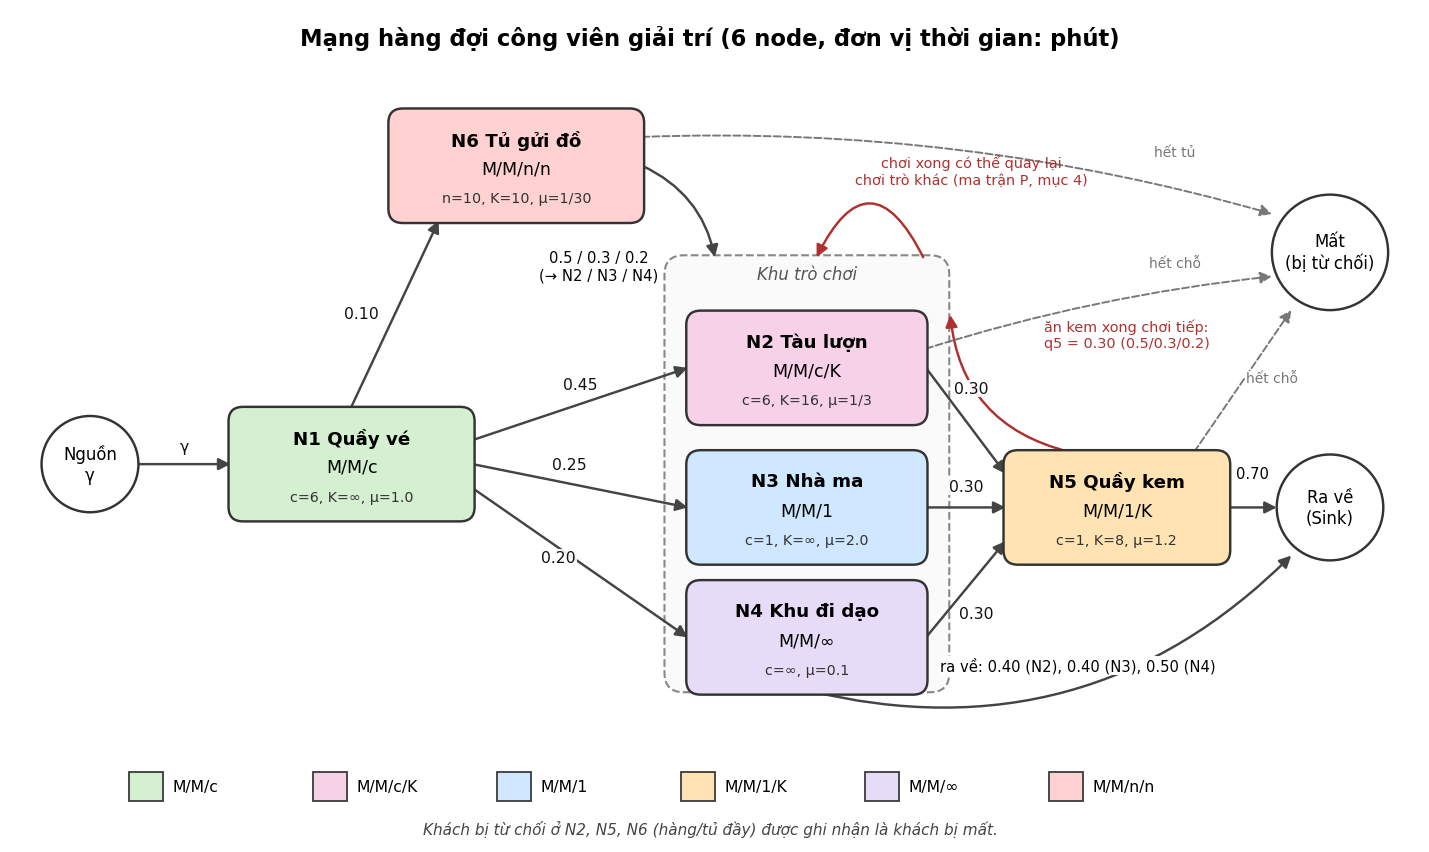

Mạng có rẽ nhánh (sau quầy vé, khách chia thành 4 hướng), hợp (nhiều trò cùng dẫn đến quầy kem) và vòng quay lại (chơi xong có thể chơi tiếp trò khác; ăn kem xong cũng có thể quay lại khu trò chơi với xác suất $q_5$). Khách bị từ chối ở N2, N5, N6 (nét đứt) rời hệ thống và được tính là mất.

**Hình 2. Kiến trúc mô phỏng trên `bkitevsim`**

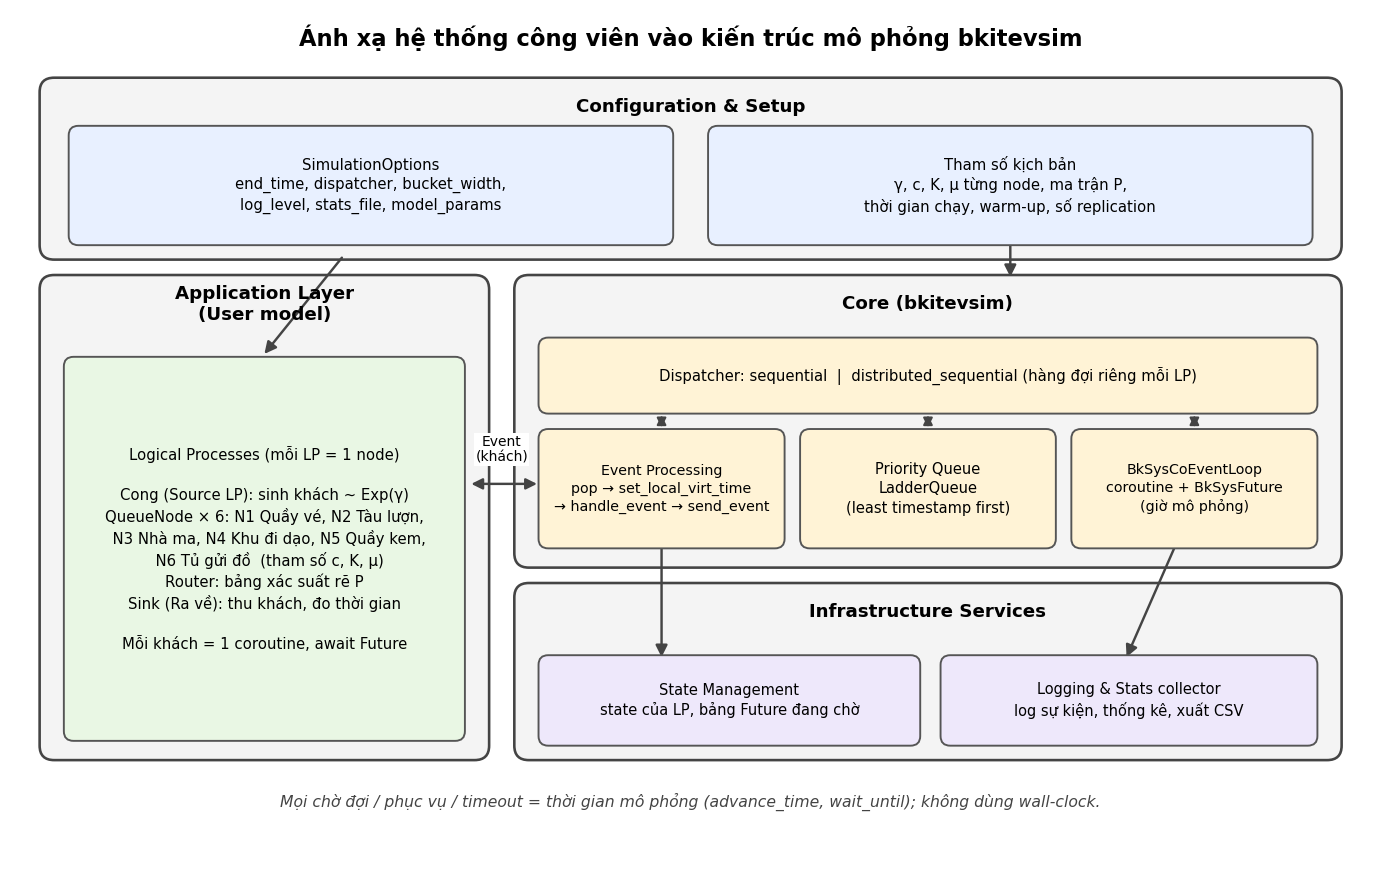

Kiến trúc gồm 4 lớp: Configuration & Setup (cấu hình), Application Layer (các LP node), Core (Dispatcher, LadderQueue, xử lý sự kiện, event loop coroutine) và Infrastructure Services (quản lý trạng thái, ghi log và thống kê). Sơ đồ chi tiết và class diagram bổ sung ở Phase 2.

### Các thành phần hệ thống

#### 1. Đặc tả thành phần

- **Nguồn (Source).** Sinh khách theo quá trình Poisson tốc độ $\gamma$; mỗi khách có mã định danh và thời điểm đến cổng; khách mới được gửi vào N1.
- **N1 Quầy vé (M/M/c, c=6, K=∞).** Khách xếp một hàng chung, quầy rảnh nào phục vụ trước. Xong thì rẽ vào N2, N3, N4 hoặc N6.
- **N2 Tàu lượn (M/M/c/K, c=6, K=16).** Khi số khách trong node đạt 16, khách đến sau bị từ chối. Xong thì rẽ vào N3, N4, N5 hoặc ra về.
- **N3 Nhà ma (M/M/1).** Một lối vào, hàng chờ không giới hạn. Xong thì rẽ vào N2, N4, N5 hoặc ra về.
- **N4 Khu đi dạo (M/M/∞).** Khách được phục vụ ngay (ở lại trung bình 10 phút), không xếp hàng. Xong thì rẽ vào N2, N3, N5 hoặc ra về.
- **N5 Quầy kem (M/M/1/K, K=8).** Một nhân viên, hàng chờ giới hạn; đầy thì từ chối. Xong thì chơi tiếp (xác suất $q_5=0.30$, chọn N2 / N3 / N4 theo tỉ lệ 0.5 / 0.3 / 0.2) hoặc ra về (0.70).
- **N6 Tủ gửi đồ (M/M/n/n, n=10).** Còn tủ thì nhận, hết tủ thì từ chối ngay. Gửi xong khách rẽ vào N2, N3 hoặc N4.
- **Sink.** Thu khách ra về, ghi thời gian khách ở trong công viên.

#### 2. Luồng hoạt động

1. Source sinh khách tại thời điểm mô phỏng $t$ và lên lịch lần đến kế tiếp sau một khoảng ~ Exp($\gamma$).
2. Khách đến N1: có server rảnh thì được phục vụ ngay, không thì vào hàng chờ.
3. Khi kết thúc phục vụ ở một node, khách chọn node kế tiếp theo ma trận xác suất rẽ hoặc ra về.
4. Nếu node kế tiếp có giới hạn (N2, N5, N6) và đã đầy, khách bị từ chối: ghi nhận khách mất và kết thúc hành trình.
5. Khi khách ra về, Sink ghi thời gian ở trong công viên và số lượt chơi.
6. Mô phỏng dừng ở $T_{end}$; thống kê chỉ tính sau thời gian khởi động.

#### 3. Tổng kết

| Thành phần | Vai trò | Mô hình | Sự kiện chính |
|---|---|---|---|
| Source | Sinh khách | Poisson($\gamma$) | `ARRIVAL` |
| N1 | Bán vé | M/M/c | `END_SERVICE` |
| N2 | Tàu lượn | M/M/c/K | `END_SERVICE`, `REJECT` |
| N3 | Nhà ma | M/M/1 | `END_SERVICE` |
| N4 | Khu đi dạo | M/M/∞ | `END_SERVICE` |
| N5 | Quầy kem | M/M/1/K | `END_SERVICE`, `REJECT` |
| N6 | Tủ gửi đồ | M/M/n/n | `END_SERVICE`, `REJECT` |
| Sink | Thu khách ra về | Bộ thu thống kê | `DEPART` |

### Các module hệ thống

#### 1. Các thành phần mô phỏng

Hệ thống gồm 3 thành phần: Arrival event, Server và Processing event.

| Thành phần | Trong hệ thống |
|---|---|
| Arrival event (`mean_interarrival_time`) | LP `Source`: sinh khách, `mean_interarrival_time = 1/γ` |
| Server (`mean_servicetime`, `maxServer`) | LP `QueueNode` với $\mu$, $c$, $K$; thao tác `arrival()`, `schedule()`, `run()` (nhận khách, kiểm tra chỗ, lên lịch) và `beginService()`, `endService()` (bắt đầu phục vụ, giải phóng server và chọn node kế tiếp) |
| Processing event (`create()`) | Sự kiện ghi log và thông báo: đến, bắt đầu, xong, từ chối, ra về |

#### 2. Các lớp chính và sự kiện (dự kiến, hoàn thiện ở Phase 2)

| Lớp | Vai trò | Thuộc tính chính | Phương thức chính |
|---|---|---|---|
| `ParkConfig` | Cấu hình một kịch bản | `gamma`, danh sách node (c, K, μ), ma trận `P`, `t_end`, `warmup`, `seed`, `dispatcher` | `validate()`: hàng của P có tổng ≤ 1 và từ mọi node đều có đường ra về |
| `Source` (LP) | Sinh khách | `mean_interarrival_time`, `first_node_id`, bộ sinh số ngẫu nhiên | `coroutine_run()`: chờ ~ Exp rồi gửi `ARRIVAL` |
| `QueueNode` (LP) | Một node (c, K, μ) | `mean_servicetime`, `maxServer`, `maxSystemSize`, số server bận, hàng chờ, bộ đếm | `arrival()`, `schedule()`, `begin_service()`, `end_service()`, `run()` |
| `Router` | Chọn node kế tiếp | Một hàng của ma trận `P` | `choose_next(node_id)`: id node hoặc `EXIT` |
| `Sink` (LP) | Thu khách ra về | Bộ đếm, thời gian trong công viên | Xử lý `DEPART` |
| `StatsCollector` | Tích lũy thống kê | Tích phân theo thời gian (L, Lq, ρ), mẫu (W, Wq), bộ đếm mất | `record_*()`, `summary()` |
| `Theory` | Công thức lý thuyết | Không có trạng thái | `metrics(kind, λ, μ, c, K)`, `solve_traffic(γ, P, nodes, reduced)` |
| `Experiment` | Chạy thí nghiệm | Danh sách kịch bản, số lần chạy | `run_scenario(config, seed)`, `run_replications(config, R=30)`, `confidence_interval()` |

| Sự kiện | Từ → Đến | Ý nghĩa | Payload |
|---|---|---|---|
| `ARRIVAL` | Source/Node → Node | Khách đến một node | mã khách, thời điểm đến cổng, thời điểm đến node |
| `END_SERVICE` | Node → chính nó | Hết phục vụ | mã khách |
| `REJECT` | Node → bộ thống kê | Khách bị từ chối | mã khách, node |
| `DEPART` | Node → Sink | Khách ra về | mã khách, tổng thời gian |

#### 3. Xử lý bất đồng bộ (non-blocking)

Khách mới liên tục đến cổng trong khi các khách trước còn đang xếp hàng hoặc được phục vụ, nên các tác vụ cần tiến triển đồng thời mà không chặn nhau. Mỗi node là một LP kế thừa `BkSysCoLogicalProcess`: phần chờ và phục vụ viết bằng coroutine, tiến thời gian bằng `advance_time`. Source giữ một `BkSysFuture` cho mỗi khách để nhận thông báo khách đã ra về hoặc bị mất, nên có thể tiếp tục sinh khách mới mà không chờ khách trước.

**Hình 3. Luồng chạy một lần mô phỏng (Event simulation)**

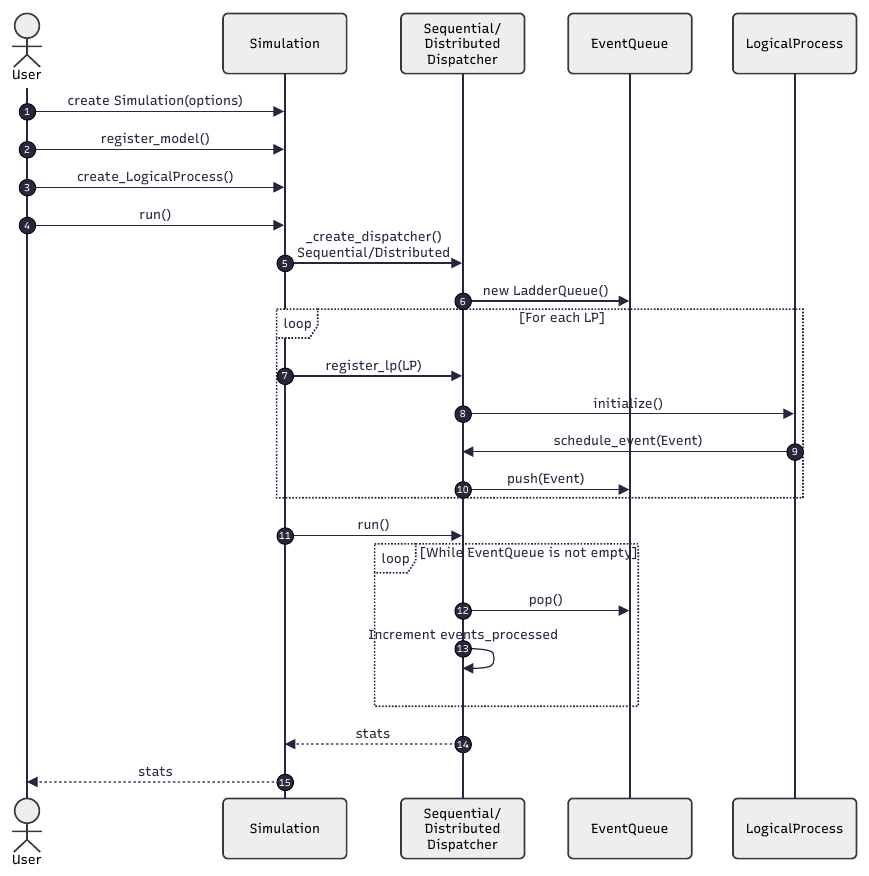

Người dùng tạo `Simulation(options)`, đăng ký model và tạo các LP của công viên (`Source`, N1–N6, `Sink`), rồi gọi `run()`. `Simulation` tạo dispatcher (sequential hoặc distributed) cùng hàng đợi sự kiện LadderQueue. Với mỗi LP, dispatcher đăng ký LP rồi gọi `initialize()`; LP lên lịch sự kiện đầu tiên (ở đây `Source` lên lịch `ARRIVAL` đầu tiên) và dispatcher đẩy sự kiện vào hàng đợi. Sau đó dispatcher lặp lấy sự kiện cho đến khi hàng đợi rỗng hoặc hết thời gian mô phỏng, đếm số sự kiện đã xử lý và trả thống kê (`stats`) về cho người dùng.

**Hình 4. Vòng lặp sự kiện (Event loop)**

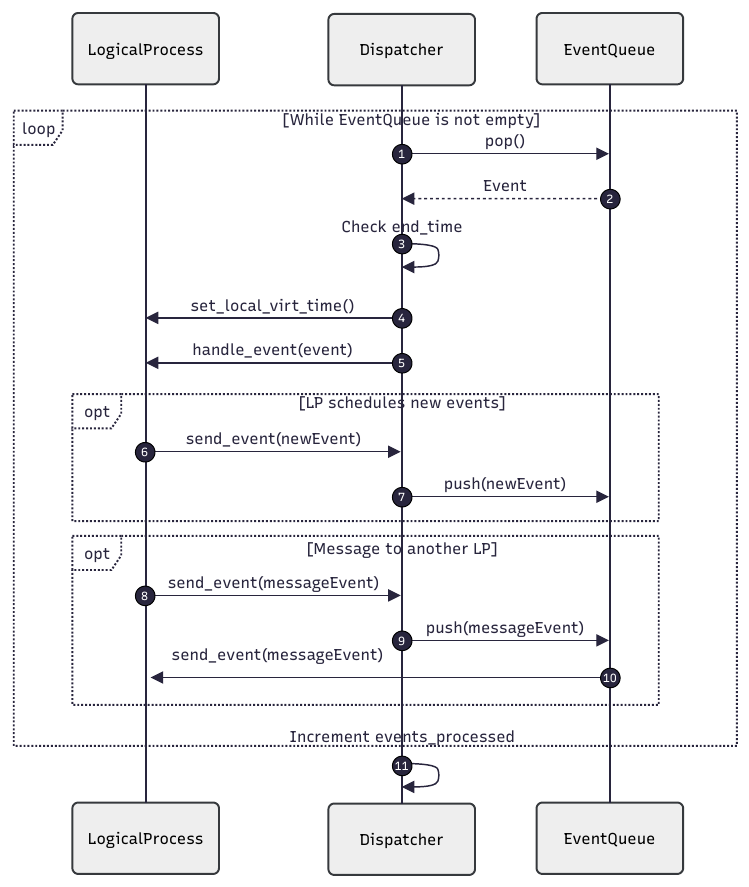

| Bước trong sơ đồ | Trong dự án công viên |
|---|---|
| 1–2. `pop()` lấy sự kiện từ hàng đợi | Dispatcher lấy `ARRIVAL` hoặc `END_SERVICE` có timestamp nhỏ nhất |
| 3. Kiểm tra `end_time` | Dừng khi timestamp vượt $T_{end}$ (10 000 phút) |
| 4. `set_local_virt_time()` | Đặt giờ cục bộ của node nhận sự kiện bằng timestamp sự kiện, không bao giờ giảm |
| 5. `handle_event(event)` | Node xử lý: `ARRIVAL` thì nhận khách hoặc `REJECT` nếu đầy; `END_SERVICE` thì giải phóng server và chọn node kế tiếp |
| 6–7. LP lên lịch sự kiện mới (tùy chọn) | Node lên lịch `END_SERVICE` cho khách vừa bắt đầu phục vụ; `Source` lên lịch `ARRIVAL` kế tiếp |
| 8–10. Gửi sự kiện cho LP khác (tùy chọn) | Khách xong ở một node: node gửi `ARRIVAL` sang node kế theo ma trận $P$, hoặc `DEPART` sang `Sink` |
| 11. Tăng `events_processed` | Bộ đếm sự kiện đã xử lý, đưa vào thống kê của lần chạy |

Vòng lặp này là cơ chế non-blocking của hệ thống: một node đang chờ hoặc đang phục vụ không chặn node khác, vì mọi việc chỉ là sự kiện nằm trong hàng đợi và thời gian tiến theo timestamp chứ không theo đồng hồ thật. Hai sơ đồ lấy từ đề bài; tên lớp và lời gọi cụ thể sẽ xác nhận ở Phase 2.

| Thành phần | Vai trò trong hệ thống | Hiện thực |
|---|---|---|
| Hàng đợi sự kiện | Giữ sự kiện chưa xử lý theo thứ tự thời gian | LadderQueue (sắp theo timestamp) |
| Bộ lập lịch tác vụ | Chạy các coroutine sẵn sàng, không chặn coroutine khác | `BkSysCoEventLoop` |
| Thông báo hoàn thành | Đánh thức tác vụ đang chờ khi khách xong hoặc bị từ chối | `BkSysFuture` gắn với mã khách; `END_SERVICE` hoặc `REJECT` giải phóng future |
| Thứ tự nhân quả | Sự kiện xử lý đúng thứ tự; khách không đến node sau trước khi rời node trước | Dispatcher lấy sự kiện theo timestamp; kiểm tra local virtual time không giảm |
| Vòng đời tác vụ | Tạo, hoàn thành, hủy, quá hạn, lỗi | Tạo: sinh khách. Hoàn thành: ra về. Hủy/quá hạn: sự kiện theo thời gian mô phỏng (mở rộng: khách bỏ hàng). Lỗi: bị từ chối khi node đầy |

| Cơ chế `asyncio` | Dùng cho |
|---|---|
| `Future` / `BkSysFuture` | Báo hiệu khách hoàn thành hoặc bị mất |
| `gather` | Chạy song song các coroutine server của một node, hoặc các tác vụ độc lập |
| `TaskGroup` | Gom các coroutine của một lần chạy; lỗi thì hủy cả nhóm |
| `as_completed` | Ghi nhận khách theo thứ tự hoàn thành |
| `Runner` | Mỗi lần chạy lặp trong event loop riêng, sạch trạng thái |
| Custom event loop | `BkSysCoEventLoop` điều khiển thời gian mô phỏng |

**Thời gian mô phỏng độc lập với thời gian thực.** Kết quả mô phỏng không được phụ thuộc vào tốc độ máy, nên mọi chờ đợi, phục vụ và timeout đều theo thời gian mô phỏng (`advance_time`, `wait_until`, sự kiện lên lịch). Không dùng `asyncio.sleep` thật và không dùng tham số `timeout` của `wait_for` (tính theo giây thực).

**Cách chạy của một node** (mã giả):

```
QueueNode.coroutine_run():
    lặp lại:
        sự kiện = chờ ARRIVAL hoặc END_SERVICE
        nếu ARRIVAL:
            nếu số khách trong node == K: gửi REJECT, giải phóng future của khách
            ngược lại: nếu có server rảnh -> begin_service, nếu không -> vào hàng chờ
        nếu END_SERVICE:
            giải phóng server; nếu hàng chờ còn khách -> begin_service
            chọn node kế tiếp bằng Router; gửi ARRIVAL (hoặc DEPART nếu ra về)
```

Các chi tiết gọi API của `bkitevsim` (cách gắn future, hành vi của `distributed_sequential`) sẽ được xác nhận bằng một chương trình thử (PoC) M/M/1 ở đầu Phase 2.

#### 4. Kế hoạch kiểm tra mô hình

**Verification** :

| Kiểm tra | Cách làm | Tiêu chí |
|---|---|---|
| Từng node độc lập | Cắt riêng node, cấp tải Poisson, so với công thức: N1 với M/M/c, N2 với M/M/c/K, N3 với M/M/1, N4 với M/M/∞, N5 với M/M/1/K, N6 với Erlang B; mỗi node thử ít nhất 3 mức tải (ổn định thấp, cao, và quá tải với node hữu hạn) | Giá trị lý thuyết nằm trong khoảng tin cậy 95%; sai số tương đối dưới 5% |
| Bảo toàn khách | Số khách đến = số ra về + số bị mất + số còn trong hệ | Khớp tuyệt đối |
| Thứ tự thời gian | Trace sự kiện có timestamp không giảm; local virtual time không giảm | Không có vi phạm |
| Tái lập | Cùng seed | Kết quả giống hệt |
| Hai dispatcher | Chạy `sequential` và `distributed_sequential` (cần xác nhận cả hai chạy được LP coroutine; nếu không thì so sánh ở bản LP đồng bộ) | Thống kê tương đương |
| Độc lập với thời gian thực | Chạy khi máy tải nặng/nhẹ | Kết quả không đổi |

**Validation**:

| Kiểm tra | Cách làm | Tiêu chí |
|---|---|---|
| Định luật Little | Kiểm tra tại từng node: $L_i=\lambda_{eff,i}W_i$ và $L_{q,i}=\lambda_{eff,i}W_{q,i}$. | Sai số tương đối dưới 3%; các đại lượng phải được tính trên cùng nhóm khách và cùng khoảng quan sát. |
| Bảo toàn số lượng khách | Kiểm tra phương trình: $N_{start}+N_{arrived}=N_{departed}+N_{lost}+N_{remaining}$. | Hai vế bằng nhau tại cuối khoảng quan sát; không có khách bị thiếu hoặc đếm trùng. |
| Lưu lượng từng node | So $\lambda_i$ đo được với nghiệm phương trình lưu lượng (offered, reduced). | Khớp ở WL1, WL2; giải thích sai lệch ở WL3. |
| Chỉ số cả mạng | So chỉ số đo được với xấp xỉ lý thuyết ở 3 workload. | Đúng xu hướng; sai lệch được giải thích. |
| Hành vi hợp lý | Tăng $\gamma$ thì thời gian chờ tăng; thêm server thì thời gian chờ giảm. | Đúng chiều ở các node có điều kiện so sánh tương ứng. |
| (Tùy chọn) Số liệu thực | Quan sát thời gian xếp hàng ở một khu vui chơi. | Cùng bậc độ lớn. |
#### 5. Giả định, hạn chế và rủi ro

**Giả định:** khách đến theo Poisson dừng; thời gian phục vụ phân phối mũ; kỷ luật FCFS; quần thể vô hạn; khách chọn node kế tiếp độc lập với lịch sử (ma trận Markov nên khách có thể ăn kem nhiều lần, sau mỗi trò); các quyết định (ăn kem, chơi tiếp, ra về, chọn trò) diễn ra tức thời; bỏ qua thời gian đi giữa các node (N4 đại diện cho thời gian di chuyển); khách bị từ chối ở N2, N5, N6 được tính là mất, kể cả khi đã chơi trước đó, và không thử lại.

**Hạn chế:**
- Lý thuyết cả mạng chỉ là xấp xỉ vì luồng ra của N2, N5, N6 không còn Poisson; kiểm tra chính xác thực hiện trên từng node riêng, cả mạng chỉ đối chiếu xấp xỉ.
- Khách bị từ chối tủ gửi đồ rời công viên là giả định đơn giản; thực tế khách có thể vẫn vào chơi.
- Tải đến dừng, chưa mô phỏng giờ cao điểm trong ngày.

**Rủi ro:**

| Rủi ro | Cách xử lý |
|---|---|
| Tài liệu `bkitevsim` chỉ có chữ ký hàm, chưa có ví dụ | Viết PoC M/M/1 sớm ở đầu Phase 2 |
| Mô phỏng lệch lý thuyết ở tải cao | Dùng reduced-load; kiểm tra từng node riêng |
| Vô tình dùng timeout theo thời gian thực | Tự cài timeout bằng sự kiện theo thời gian mô phỏng; kiểm tra độc lập với thời gian thực |
| Khối lượng thí nghiệm lớn (30 lần × nhiều kịch bản) | Chạy tự động, seed cố định, giới hạn $T_{end}$ |
| Vòng quay lại gây lặp vô hạn | `validate()` kiểm tra từ mọi node có đường ra về |

**Mở rộng dự kiến (nếu còn thời gian):** khách bỏ hàng khi chờ quá lâu (timeout theo thời gian mô phỏng); đường nhanh (fast-lane) ưu tiên ở tàu lượn; tải đến thay đổi theo giờ.

#### 6. Kế hoạch thực hiện

| Giai đoạn | Thời gian | Công việc | Sản phẩm |
|---|---|---|---|
| Phase 1: Thiết kế | Tuần 1–2 | Đặc tả hệ thống, metrics, yếu tố, workload, sơ đồ; PoC M/M/1 với `bkitevsim` | `Spe-Ass-Spec-<GroupName>.pdf` |
| Phase 2: Cài đặt | Tuần 3–4 | Cài `QueueNode` (6 cấu hình), Source, Router, Sink, StatsCollector; kiểm tra từng node; chạy workload và kịch bản; phân tích | `Spe-Ass-final-<GroupName>.zip` (Phase 1, sơ đồ kiến trúc và class, mô tả workload, mô tả thí nghiệm, validation và evaluation, user manual) |
| Phase 3: Kiểm tra chéo | Tuần 5 | Đánh giá chéo với nhóm khác: phương pháp verification, bằng chứng kiểm thử, dữ liệu validation | Báo cáo đánh giá chéo |

